# Processing monocular and binocular data

In [1]:
import pypillometry as pp
import numpy as np

Data in `pypillometry` can contain different *variables* from different *eyes*. The variables and eyes supported when importing raw data are

- `left_x`, `right_x` (x-coordinate in screen coordinates from the eyetracker)
- `left_y`, `right_y` (y-coordinate in screen coordinates from the eyetracker)
- `left_pupil`, `right_pupil` (pupil size from left and right eye)

Depending on which class is chosen (`PupilData`, `GazeData` or `EyeData`), some of these variables are required:

- `PupilData`: requires at least one of `left_pupil`, `right_pupil` (or both)
- `GazeData`: requires at least one of `(left_x, left_y)` and/or `(right_x, right_y)`
- `EyeData`: requires `x`, `y` and `pupil` from at least one eye

For example, let's simulate some basic data:

In [2]:
rng = np.random.default_rng(42)
n = 1000
left_x, right_x = rng.normal(size=n), rng.normal(size=n)
left_y, right_y = rng.normal(size=n), rng.normal(size=n)
left_pupil, right_pupil = rng.normal(size=n), rng.normal(size=n)
time = np.arange(n)  # time in ms

# these are all ok
dpupil = pp.PupilData(left_pupil=left_pupil, right_pupil=right_pupil, time=time)
dgaze = pp.GazeData(left_x=left_x, left_y=left_y, right_x=right_x, right_y=right_y, time=time)
deye = pp.EyeData(left_x=left_x, left_y=left_y, left_pupil=left_pupil, time=time)

Creating an `EyeData` object without pupil data, on the other hand, fails:

In [3]:
pp.EyeData(left_x=left_x, time=time)

ValueError: At least one of the eye-traces must be provided (both x and y)

Once the data is loaded, we can check which variables and eyes are available using the `.eyes` and `.variables` attributes:

In [4]:
deye.eyes, deye.variables

(['left'], ['x', 'y', 'pupil'])

Simply printing an object also shows which data are available and gives a glimpse into the data:

EyeData(femuhulu, 55.4KiB):
 n                 : 1000
 sampling_rate     : 1000.0
 eyes              : ['left']
 data              : ['left_x', 'left_y', 'left_pupil']
 nevents           : 0
 experimental_setup: not set
 calibration       : not available
 duration_minutes  : 0.016666666666666666
 start_min         : 0.0
 end_min           : 0.01665
 parameters        : {}
 glimpse           : EyeDataDict(vars=3,n=1000,shape=(1000,)): 
  left_x (float64): 0.30471707975443135, -1.0399841062404955, 0.7504511958064572, 0.9405647163912139, -1.9510351886538364...
  left_y (float64): -0.4519509798535085, -0.6658777111204364, 0.43400982345010697, 0.25185441529500513, -1.4047915476103274...
  left_pupil (float64): 0.2532045102953498, 0.8952184022261802, 0.2733212565368742, 2.238831666414424, 1.4297874524704182...

 nblinks           : {}
 blinks            : {'left': None}
 params            : {}
 History:
 *
 └ fill_time_discontinuities()
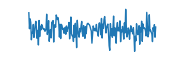
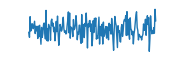
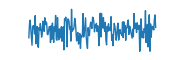

In [5]:
deye

In [6]:
d = pp.get_example_data("rlmw_002_short")
d.eyes, d.variables

(['left', 'right'], ['x', 'y', 'pupil'])

Almost all of `pypillometry`'s functions have keyword arguments `eyes=` and `variables=` that specify which eyes/variables to operate on. By default, all variables and eyes are processed.

For example, we can run the `scale()` function that re-scales the data to have mean 0 and standard deviation 1.
Here, we use the context manager `pp.loglevel("DEBUG")` to see what `pypillometry` does internally:

In [7]:
with pp.loglevel("DEBUG"):
    deye.scale(eyes="left")

pp: 12:35:28 | DEBUG    | _get_eye_var:457 | scale(): eyes=['left'], vars=['x', 'y', 'pupil']


pp: 12:35:28 | DEBUG    | scale:2174 | Mean: {'left': {'x': np.float64(-0.028891550995946837), 'y': np.float64(0.03370120480230512), 'pupil': np.float64(-0.02135748147595793)}}


pp: 12:35:28 | DEBUG    | scale:2175 | SD: {'left': {'x': np.float64(0.988722355396508), 'y': np.float64(1.0161916099991923), 'pupil': np.float64(0.9978409919199771)}}


The output shows that all variables of the left eye have been processed.

## Which functions work on which data?

Not all of `pypillometry`'s functions can be applied to all variables. Functions that are specific to pupil data have the prefix `pupil_` and functions that only work on gaze (x/y) data have the prefix `gaze_`. The other functions operate on all variables (which may or may not make sense, it is up to you to check!).

Functions that work only on pupillometric data are implemented in the `PupilData` class and are therefore not available for `GazeData`:

In [8]:
dpupil.pupil_blinks_detect()  # works fine

{'left_pupil': Intervals 'left_pupil_blinks' | 0 intervals | fs=1000.0Hz,
 'right_pupil': Intervals 'right_pupil_blinks' | 0 intervals | fs=1000.0Hz}

In [9]:
dgaze.pupil_blinks_detect()  # fails

AttributeError: 'GazeData' object has no attribute 'pupil_blinks_detect'

Functions that are implemented in `GenericEyeData` work for both:

GazeData(falilidi, 71.7KiB):
 n                 : 1000
 sampling_rate     : 1000.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'right_x', 'right_y']
 nevents           : 0
 experimental_setup: not set
 calibration       : not available
 duration_minutes  : 0.016666666666666666
 start_min         : 0.0
 end_min           : 0.01665
 parameters        : {scale: {...}}
 glimpse           : EyeDataDict(vars=4,n=1000,shape=(1000,)): 
  left_x (float64): 0.3374138643973422, -1.0226253606241862, 0.788232148842092, 0.9805141575850979, -1.9440681473082007...
  left_y (float64): -0.4779139877529589, -0.6884320919784975, 0.39393025361439465, 0.21467724034138935, -1.4155723568843241...
  right_x (float64): 0.021789903880582735, -0.6389415199887559, -0.32848467675525184, 0.7053891288457165, 0.08320394147533162...
  right_y (float64): 1.281415429921478, 0.7061990375540406, 2.0162595417236044, -1.584627149316187, -0.27042933108889905...

 History:
 *
 └ fill_time_discontinuities()
  └ scale()
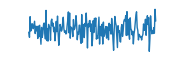
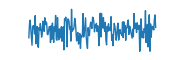
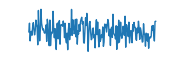
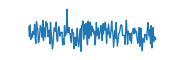

In [10]:
dpupil.scale()  # works
dgaze.scale()  # works

## Creating new variables or eyes

In some cases, new variables or "eyes" can be created. For example, we might want to reduce a binocular dataset to one where we average the timeseries from the two eyes. In that case, we can use the function `merge_eyes()`:

PupilData(monuvopa, 56.5KiB):
 n               : 1000
 sampling_rate   : 1000.0
 eyes            : ['left', 'right', 'mean']
 data            : ['left_pupil', 'right_pupil', 'mean_pupil']
 nevents         : 0
 nblinks         : {}
 blinks          : {'left': None, 'right': None, 'mean': None}
 duration_minutes: 0.016666666666666666
 start_min       : 0.0
 end_min         : 0.01665
 params          : {scale: {...}}
 glimpse         : EyeDataDict(vars=3,n=1000,shape=(1000,)): 
  left_pupil (float64): 0.27515605591930475, 0.9185590601349477, 0.29531632835190663, 2.2650794727739947, 1.4542847464646471...
  right_pupil (float64): -0.3012922434245387, -0.34204132022048095, -0.7317113159022368, 0.372173586148511, 0.18199910876591735...
  mean_pupil (float64): -0.013068093752616972, 0.2882588699572334, -0.2181974937751651, 1.318626529461253, 0.8181419276152823...

 History:
 *
 └ fill_time_discontinuities()
  └ scale()
   └ merge_eyes(eyes=['left', 'right'],variables=['pupil'],method='mean')
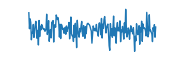
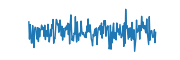
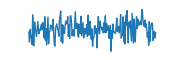

In [11]:
dpupil.merge_eyes(eyes=["left", "right"], variables=["pupil"], method="mean")

We can see that a new "eye" called `mean` with variable `pupil` (i.e., `mean_pupil`) has been created. The original data `left_pupil` and `right_pupil` have been kept (this can be changed by using `keep_eyes=False`).

In other cases, the package creates new variables. For example, the function `pupil_estimate_baseline()` estimates the tonic fluctuations in the pupil (see [Mittner & Groot, 2025](https://doi.org/10.3758/s13428-025-02755-7)) and creates a new variable `<eye>_baseline`. The baseline estimation does not work with missing data, so we first detect and interpolate blinks:

In [12]:
d = pp.get_example_data("rlmw_002_short")
d.pupil_blinks_detect(apply_mask=True)\
 .pupil_blinks_interpolate()\
 .pupil_estimate_baseline()
d.variables

['x', 'y', 'pupil', 'baseline']

## Debugging

If you want to know exactly which steps `pypillometry` is taking, and which variables/eyes are being processed,
you can use the `pp.loglevel()` context manager to temporarily increase the logging level (the result is a rather lengthy and detailed debug output):

In [13]:
with pp.loglevel("DEBUG"):
    d.pupil_lowpass_filter(cutoff=4)

pp: 12:35:29 | DEBUG    | _get_eye_var:457 | pupil_lowpass_filter(): eyes=['left', 'right'], vars=['x', 'y', 'pupil', 'baseline']
